In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [69]:
data=pd.read_csv(r'c:\Users\Admin\Desktop\New folder\HRDataset_v14.csv')
data.head(5)

,Employee_Name,EmpID,MarriedID,MaritalStatusID,GenderID,EmpStatusID,DeptID,PerfScoreID,FromDiversityJobFairID,Salary,...,ManagerName,ManagerID,RecruitmentSource,PerformanceScore,EngagementSurvey,EmpSatisfaction,SpecialProjectsCount,LastPerformanceReview_Date,DaysLateLast30,Absences
0,"Adinolfi, Wilson K",10026,0,0,1,1,5,4,0,62506,...,Michael Albert,22.0,LinkedIn,Exceeds,4.60,5,0,1/17/2019,0,1
1,"Ait Sidi, Karthikeyan",10084,1,1,1,5,3,3,0,104437,...,Simon Roup,4.0,Indeed,Fully Meets,4.96,3,6,2/24/2016,0,17
2,"Akinkuolie, Sarah",10196,1,1,0,5,5,3,0,64955,...,Kissy Sullivan,20.0,LinkedIn,Fully Meets,3.02,3,0,5/15/2012,0,3
3,"Alagbe,Trina",10088,1,1,0,1,5,3,0,64991,...,Elijiah Gray,16.0,Indeed,Fully Meets,4.84,5,0,1/3/2019,0,15
4,"Anderson, Carol",10069,0,2,0,5,5,3,0,50825,...,Webster Butler,39.0,Google Search,Fully Meets,5.00,4,0,2/1/2016,0,2


In [70]:
%matplotlib inline
plt.style.use('bmh')


In [78]:
data.groupby('PositionID')
salary = data['Salary'].dropna()
salary.interpolate()
mean_val   = salary.mean()
median_val = salary.median()
std_val    = salary.std()

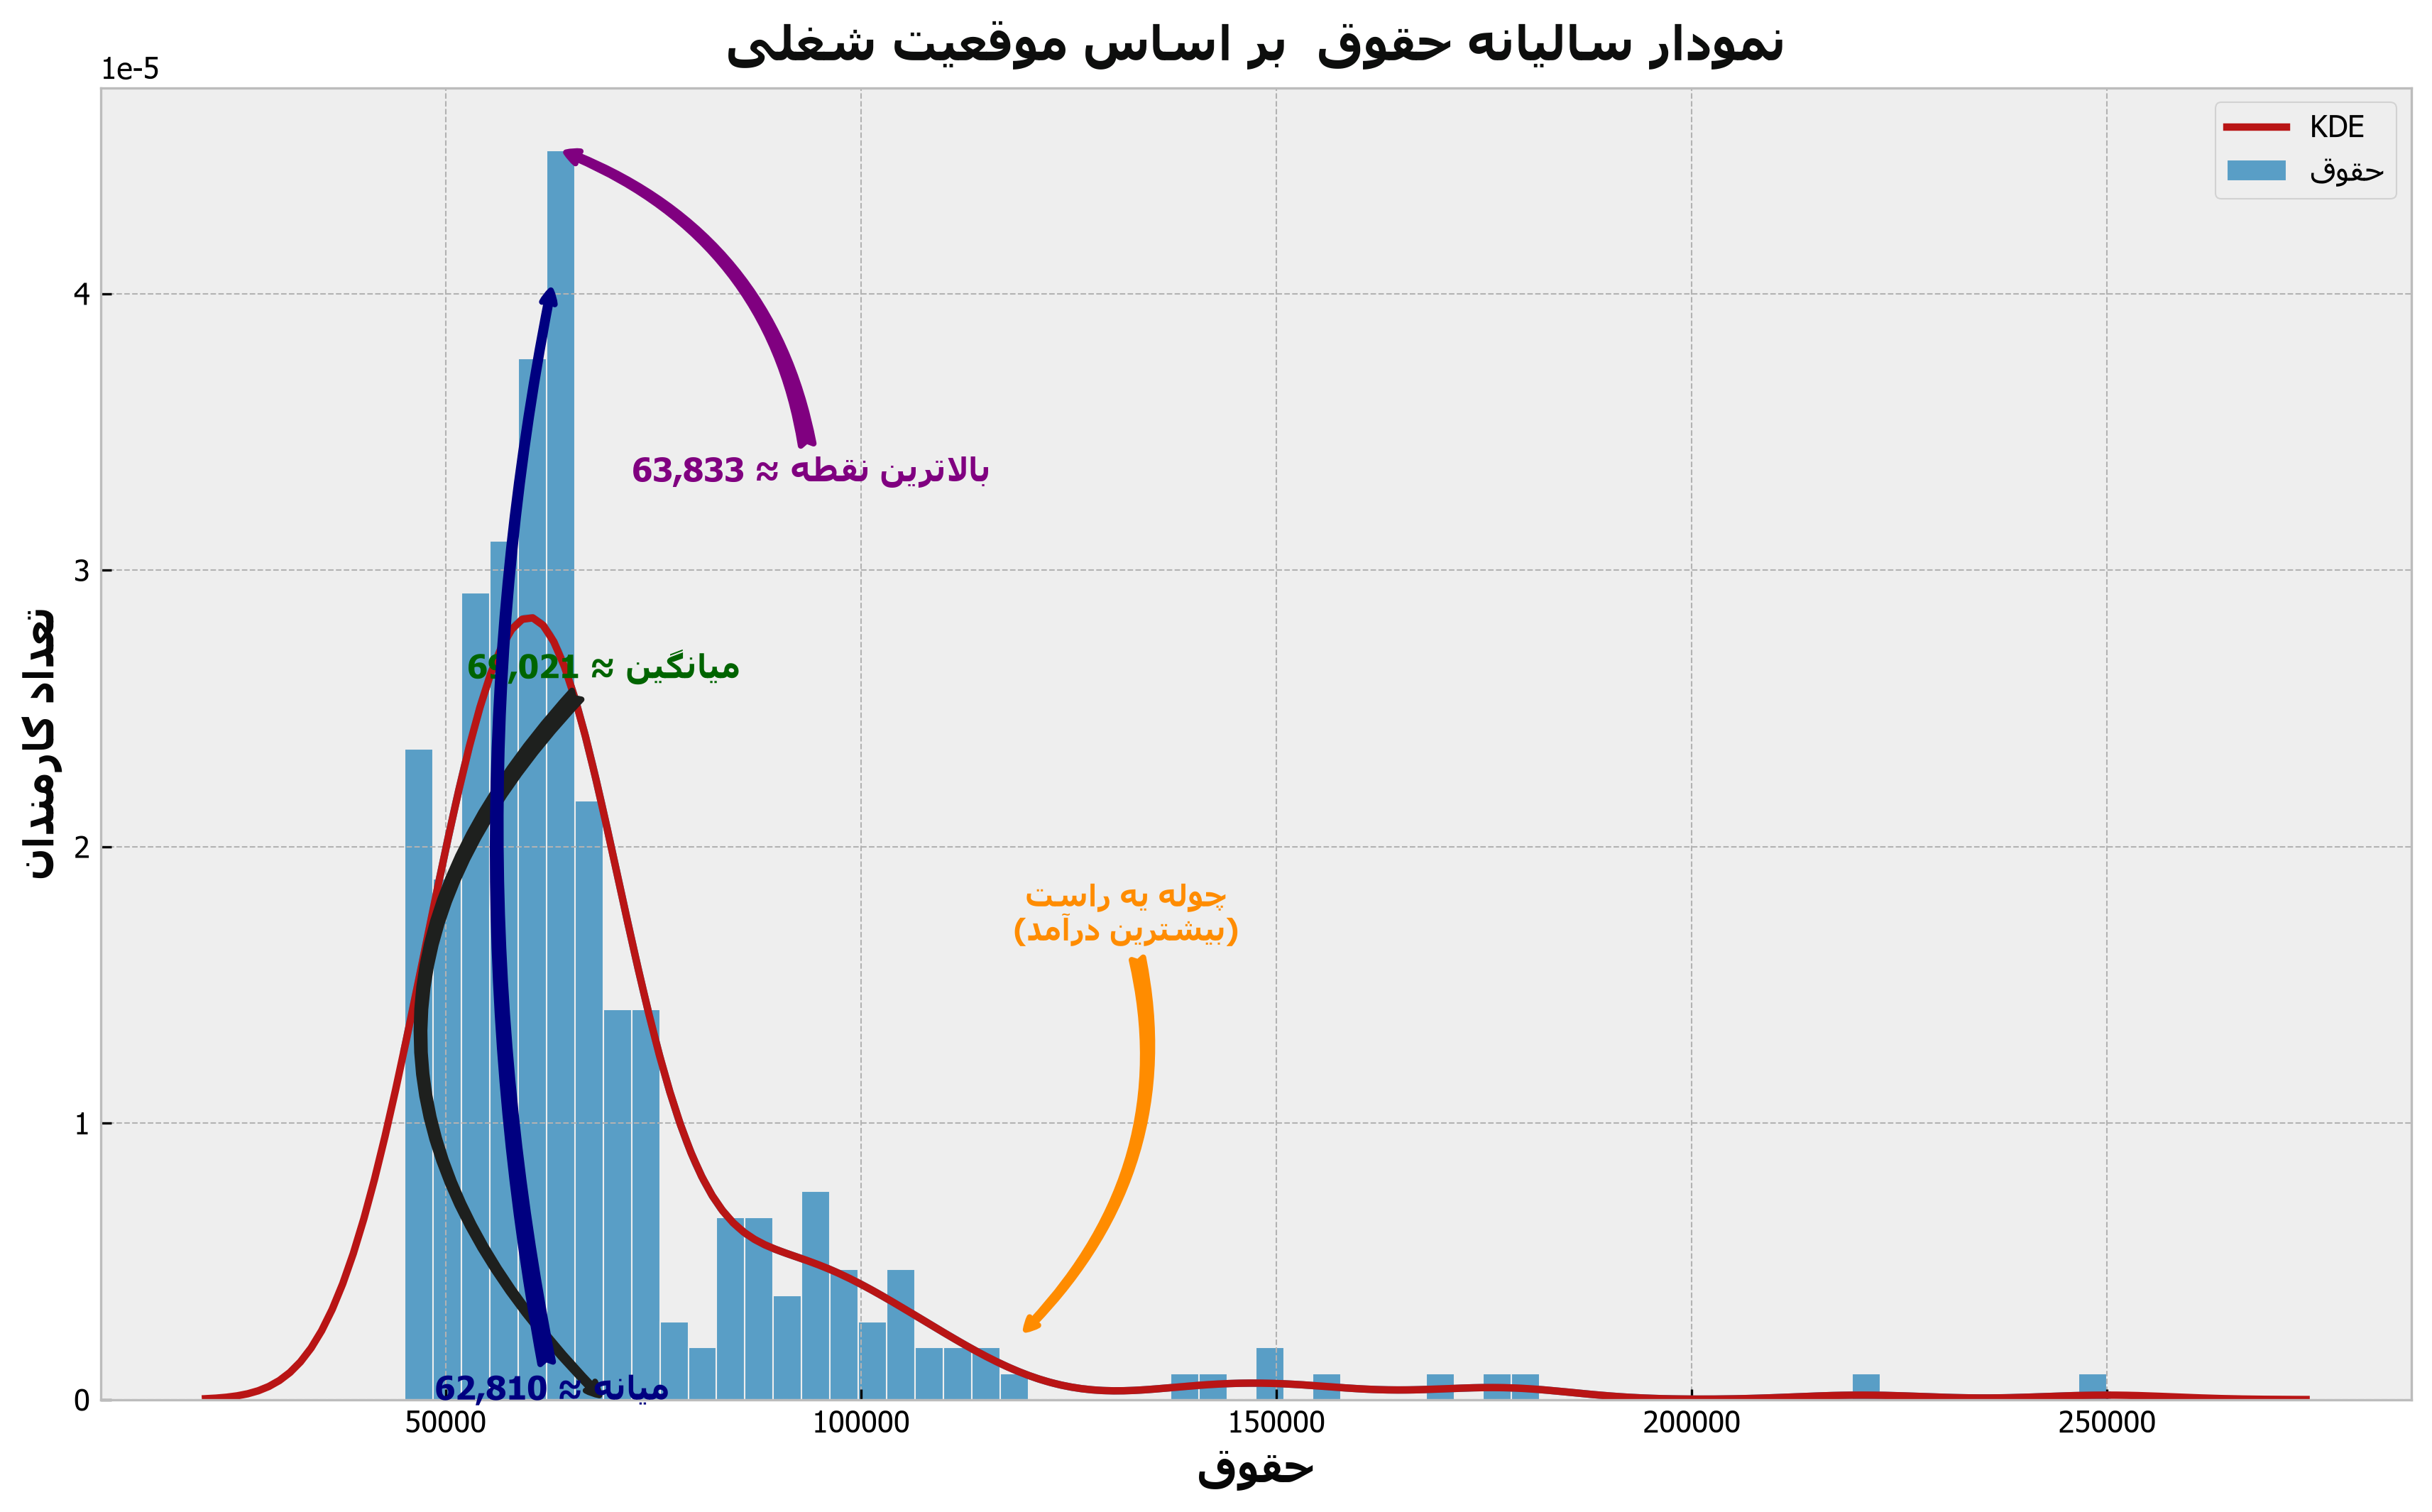

In [148]:
plt.figure(figsize=(14, 8), dpi=300)
sns.histplot(data['Salary'], bins=60, alpha=0.8, label="حقوق", kde=True,line_kws={'color': "#B91515", 'lw': 2.5}, stat='density')
plt.title("نمودار سالیانه حقوق  بر اساس موقعیت شغلی", fontdict={
    'fontsize': 16,
    'fontweight': 'bold',
    'color': "#0d0e0d",
    'verticalalignment': 'bottom'
})
sns.kdeplot(
    data['Salary'],
    color='#B91515',
    lw=2.5,
    ax=plt.gca(),
    label='KDE'
)
plt.annotate(
    f"میانگین ≈ {mean_val:,.0f}",
    xy=(mean_val, 0),
    xytext=(mean_val, y_top * 0.55),
    arrowprops=dict(arrowstyle='fancy', color="#1E201E", lw=2, connectionstyle='arc3,rad=0.5'),
    fontsize=11, color='darkgreen', fontweight='bold', ha='center',
)

plt.annotate(
    f"میانه ≈ {median_val:,.0f}",
    xy=(median_val, y_top * 0.85),
    xytext=(median_val, 0),
    arrowprops=dict(arrowstyle='fancy', color='navy', lw=2, connectionstyle='arc3,rad=-0.1'),
    fontsize=11, color='navy', fontweight='bold', ha='center',
)
right_tail = mean_val + 2 * std_val
plt.annotate(
    "چوله یه راست\n(بیشترین درآمد)",
    xy=(right_tail, y_top * 0.05),
    xytext=(right_tail + std_val * 0.5, y_top * 0.35),
    arrowprops=dict(arrowstyle='fancy', color='darkorange', lw=2, connectionstyle='arc3,rad=-0.3'),
    fontsize=10, color='darkorange', fontweight='bold', ha='center',
)
mode_height = counts.max() / len(salary) / (bin_edges[1] - bin_edges[0])
plt.annotate(
    f"بالاترین نقطه ≈ {mode_val:,.0f}",
    xy=(mode_val, mode_height),
    xytext=(mode_val + std_val * 1.2, y_top * 0.7),
    arrowprops=dict(arrowstyle='fancy', color='purple', lw=2, connectionstyle='arc3,rad=0.3'),
    fontsize=11, color='purple', fontweight='bold', ha='center')
plt.xlabel("حقوق", fontdict={'color':"#070707", 'fontsize':14,'fontweight': 'bold'})
plt.ylabel("تعداد کارمندان", fontdict={'color':"#070707", 'fontsize':14,'fontweight': 'bold'})
plt.legend()
plt.show()


این نمودار ستونی به همراه منحنی چگالی، توزیع حقوق سالیانه کارمندان را نشان میدهد. در این نمودار سه شاخص مرکزی مشخص شده است: میانگین حدود ۶۲٬۰۲۱، میانه حدود ۶۲٬۸۱۰ و نما (پرتکرارترین مقدار) حدود ۶۳٬۸۳۳. جالب اینکه میانگین از میانه کوچکتر است، که برخلاف انتظار معمول در توزیعهای چوله به راست است. دلیل این امر آن است که حجم عظیم دادهها در بازهای باریک حدود ۵۰ تا ۷۰ هزار متمرکز شده و دنباله سمت راست بسیار نازک و کمتراکم است؛ یعنی تعداد افرادی که حقوقهای بسیار بالا میگیرند آنقدر کم است که نتوانستهاند میانگین را به سمت راست بکشند. شکل توزیع چوله به راست است، چنانکه در نمودار با فلش نارنجی مشخص شده: بیشتر کارمندان حقوقی بین ۴۰ تا ۸۰ هزار دریافت میکنند و تنها شمار اندکی حقوق بالای ۱۰۰ هزار تا سقف ۲۵۰ هزار دارند که باعث ایجاد دنبالهای بلند در سمت راست شده است. بالاترین تراکم دادهها در محدوده ۶۰ تا ۶۵ هزار قرار دارد. از نظر مدیریتی، این نمودار نشان میدهد که ساختار حقوقی در سطوح پایین و میانی بسیار همگن و نزدیک به هم است، اما وجود دنباله سمت راست حاکی از وجود پستهای ارشد، مدیریتی یا تخصصی با حقوق بسیار بالاتر است. اختلاف کم میانگین و میانه نیز نشان میدهد که میانگین بهخوبی نماینده جامعه آماری است و دادههای پرت شدیدی وجود ندارد. برای بهبود نمودار پیشنهاد میشود محور عمودی به جای چگالی با نماد علمی، بر حسب تعداد یا درصد نمایش داده شود تا مخاطب تعداد واقعی کارمندان یا سهم آنها را ببیند؛ همچنین به جای فلشهای خمیده که نمودار را شلوغ کردهاند، میتوان از خطوط عمودی رنگارنگ برای نشان دادن میانگین، میانه و نما استفاده کرد و خطوط دور ستونها را کمرنگتر یا حذف کرد تا ظاهر تمیزتری ایجاد شود. در مجموع، این نمودار بیانگر آن است که حقوق در این سازمان دارای توزیعی چوله به راست است، بهگونهای که اکثریت کارمندان حقوقی نزدیک به میانگین حدود ۶۲ هزار دریافت میکنند، اما تعداد معدودی از افراد با حقوقهای بسیار بالا تا ۲۵۰ هزار در سازمان وجود دارند.